# Exploratory Data Analysis: US Superstore Retail Sales (2014–2017)

## Section 1: Executive Overview & Objectives

This notebook presents a structured exploratory data analysis (EDA) of the cleaned US Superstore retail transaction dataset (`clean_superstore.parquet`, 9,994 transaction line items spanning 2014–2017).

### Analytical Objectives
1. **Validate & Profile the Processed Dataset**: Inspect schema, row grain, data completeness, and numerical distributions (`sales`, `profit`, `quantity`, `discount`, `profit_margin_pct`, and `shipping_duration_days`).
2. **Quantify Revenue & Profit Trajectories**: Evaluate Year-over-Year (YoY) growth, Month-over-Month (MoM) volatility, and Q4 holiday seasonality.
3. **Diagnose Margin & Discount Elasticity**: Identify the exact discount threshold beyond which transactions systematically turn unprofitable, and isolate loss-making product sub-categories.
4. **Segment Customers & Regions**: Profile customer segments (`Consumer`, `Corporate`, `Home Office`), compute RFM behavioral tiers, and benchmark performance across the 4 US sales regions (`West`, `East`, `Central`, `South`).
5. **Synthesize Actionable Recommendations**: Translate quantitative findings into concrete commercial and pricing policies.


## Section 2: Data Ingestion

Load `data/processed/clean_superstore.parquet` and verify shape, data types, date coverage, and missing values.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_columns", 35)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Resolve dataset path regardless of whether notebook runs from project root or notebooks/
candidates = [
    Path("data/processed/clean_superstore.parquet"),
    Path("../data/processed/clean_superstore.parquet"),
]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Could not locate data/processed/clean_superstore.parquet")

df = pd.read_parquet(data_path)
df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"] = pd.to_datetime(df["ship_date"])

print(f"Loaded: {data_path.resolve()}")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Date Range: {df['order_date'].min().date()} to {df['order_date'].max().date()}")
print(f"Missing values across all columns: {int(df.isna().sum().sum())}")
print(f"Unique Orders: {df['order_id'].nunique():,} | Unique Customers: {df['customer_id'].nunique():,} | Unique SKUs: {df['product_id'].nunique():,}")

df.head(5)


Loaded: D:\one drive\OneDrive\Desktop\Sales-Analytics-Project\data\processed\clean_superstore.parquet
Shape: 9,994 rows x 31 columns
Date Range: 2014-01-03 to 2017-12-30
Missing values across all columns: 0
Unique Orders: 5,009 | Unique Customers: 793 | Unique SKUs: 1,862


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,state,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,order_year,order_month,order_month_name,order_quarter,order_day_name,shipping_duration_days,total_cost,profit_margin_pct,unit_selling_price,unit_cost
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91,2016,11,November,4,Tuesday,3,220.05,16.00,130.98,110.02
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58,2016,11,November,4,Tuesday,3,512.36,30.00,243.98,170.79
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87,2016,6,June,2,Sunday,4,7.75,47.00,7.31,3.87
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03,2015,10,October,4,Sunday,7,"1,340.61",-40.00,191.52,268.12
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52,2015,10,October,4,Sunday,7,19.85,11.25,11.18,9.93


**Ingestion Check & Observations**:
- All **9,994** line-item records and **31** engineered columns loaded cleanly with **0 missing values**.
- The transaction horizon spans **4 full calendar years** (`2014-01-03` through `2017-12-30`), covering **5,009** distinct orders across **793** unique customers and **1,862** product IDs.


## Section 3: Summary Statistics & Numerical Distribution

Inspect descriptive statistics (`describe()`), skewness, and visual distributions (histograms and box plots) to detect extreme outliers and heavy-tailed behavior.


In [2]:
num_cols = [
    "sales",
    "profit",
    "quantity",
    "discount",
    "profit_margin_pct",
    "shipping_duration_days",
]

summary = df[num_cols].describe().T
summary["skewness"] = df[num_cols].skew()
summary["iqr"] = summary["75%"] - summary["25%"]
summary[["count", "mean", "std", "min", "25%", "50%", "75%", "max", "iqr", "skewness"]]


,count,mean,std,min,25%,50%,75%,max,iqr,skewness
sales,"9,994.00",229.86,623.25,0.44,17.28,54.49,209.94,"22,638.48",192.66,12.97
profit,"9,994.00",28.66,234.26,"-6,599.98",1.73,8.67,29.36,"8,399.98",27.64,7.56
quantity,"9,994.00",3.79,2.23,1.00,2.00,3.00,5.00,14.00,3.00,1.28
discount,"9,994.00",0.16,0.21,0.00,0.00,0.20,0.20,0.80,0.20,1.68
profit_margin_pct,"9,994.00",12.03,46.68,-275.00,7.50,27.00,36.25,50.00,28.75,-2.89
shipping_duration_days,"9,994.00",3.96,1.75,0.00,3.00,4.00,5.00,7.00,2.00,-0.42


**Statistical Profile Observations**:
- **Extreme Positive Skew in Sales (`skewness ≈ 12.97`)**: Mean line-item sales (`$229.86`) is over **4.2x** the median (`$54.49`), driven by high-ticket enterprise/technology orders (up to `$22,638.48`).
- **Negative Skew & Heavy Tails in Profit (`profit_margin_pct` skewness `= -2.89`, `profit` skewness `= 7.56`)**: While median profit is `$8.67`, line-item profit spans from `-$6,599.98` to `+$8,399.98`, indicating severe loss outliers alongside high-margin wins.
- **Discount Concentration**: Median discount is `20%` (`0.20`), with 75% of transactions at `<= 20%` discount and an upper tail reaching `80%` clearance markdowns.


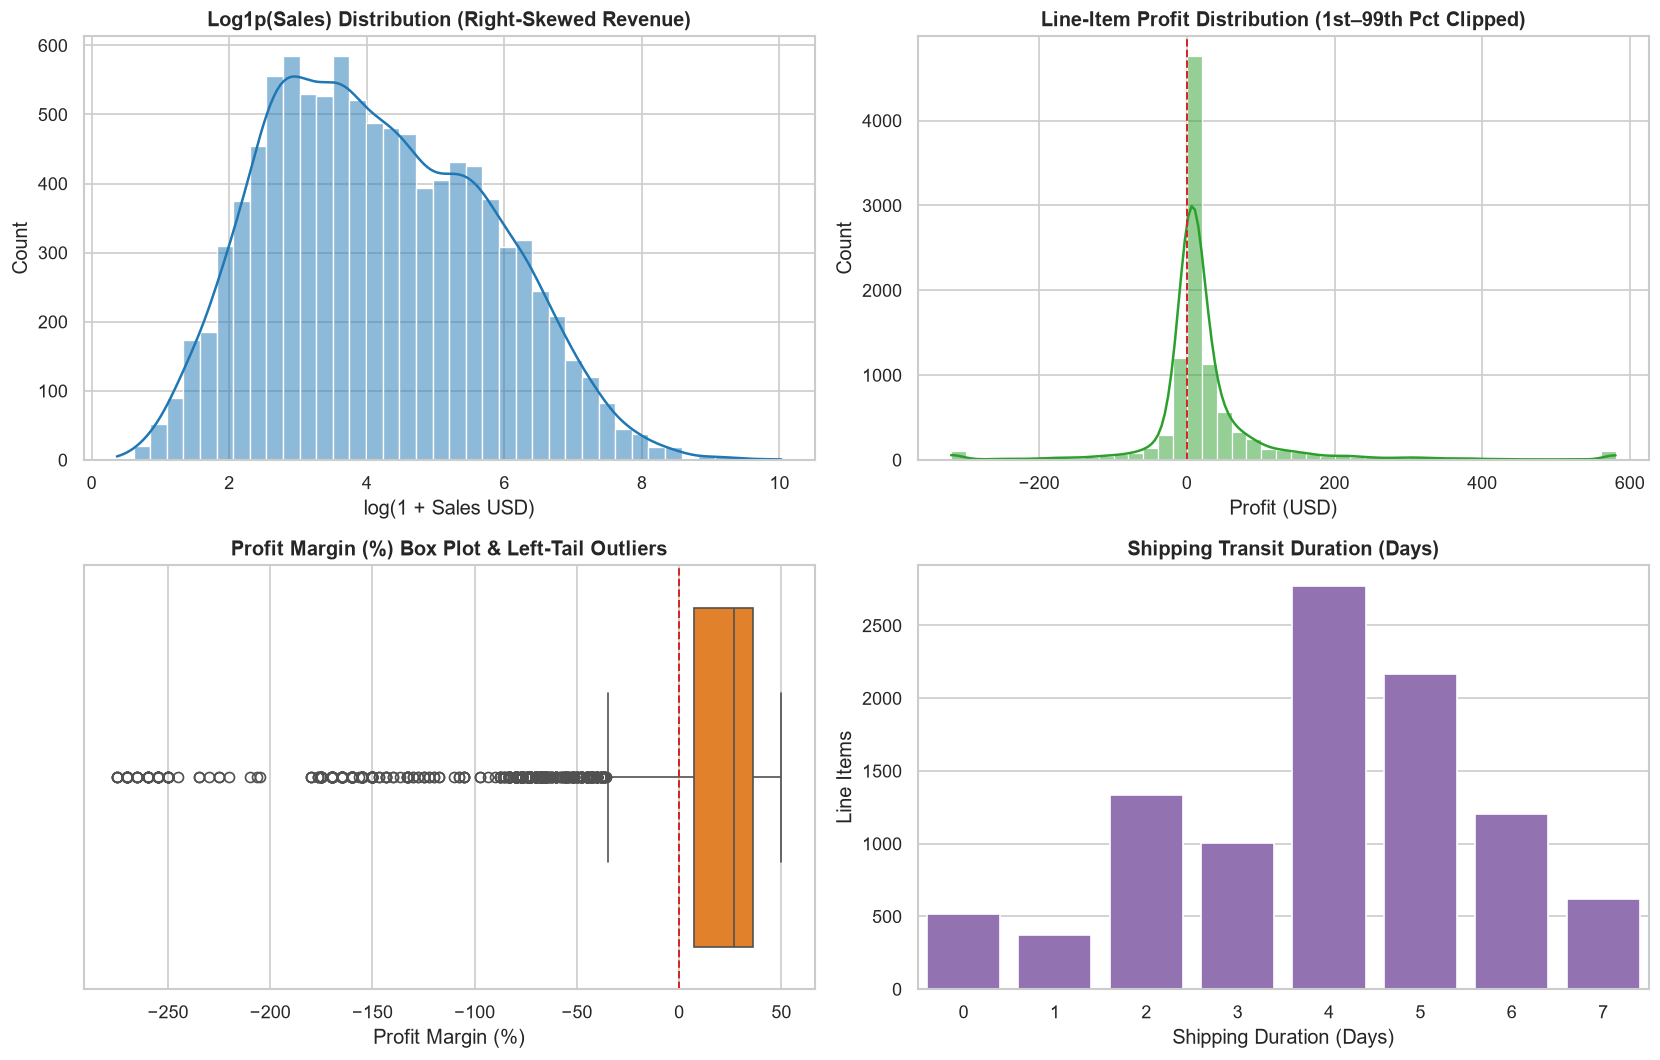

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Log-transformed Sales distribution
sns.histplot(np.log1p(df["sales"]), bins=40, kde=True, ax=axes[0, 0], color="#1f77b4")
axes[0, 0].set_title("Log1p(Sales) Distribution (Right-Skewed Revenue)", fontweight="bold")
axes[0, 0].set_xlabel("log(1 + Sales USD)")

# 2. Profit distribution (zoomed to 1st-99th percentile for readability, noting extremes)
p01, p99 = df["profit"].quantile([0.01, 0.99])
sns.histplot(df["profit"].clip(p01, p99), bins=45, kde=True, ax=axes[0, 1], color="#2ca02c")
axes[0, 1].axvline(0, color="#d62728", linestyle="--", linewidth=1.2)
axes[0, 1].set_title("Line-Item Profit Distribution (1st–99th Pct Clipped)", fontweight="bold")
axes[0, 1].set_xlabel("Profit (USD)")

# 3. Profit Margin % boxplot
sns.boxplot(x=df["profit_margin_pct"], ax=axes[1, 0], color="#ff7f0e")
axes[1, 0].axvline(0, color="#d62728", linestyle="--", linewidth=1.2)
axes[1, 0].set_title("Profit Margin (%) Box Plot & Left-Tail Outliers", fontweight="bold")
axes[1, 0].set_xlabel("Profit Margin (%)")

# 4. Quantity & Shipping Duration distribution
sns.countplot(data=df, x="shipping_duration_days", ax=axes[1, 1], color="#9467bd")
axes[1, 1].set_title("Shipping Transit Duration (Days)", fontweight="bold")
axes[1, 1].set_xlabel("Shipping Duration (Days)")
axes[1, 1].set_ylabel("Line Items")

fig.tight_layout()
plt.show()


**Distribution & Outlier Analysis**:
- `log1p(sales)` exhibits an approximately bell-shaped distribution centered around `~4.0` (`~$54`), confirming multiplicative/log-normal order-value dynamics.
- Line-item **Profit** clusters tightly around small positive margins, but displays a pronounced negative tail caused by deep-discount clearance items (pulling `profit_margin_pct` down as far as `-275%`).
- **Shipping Duration** ranges strictly from `0` to `7` days, peaking at `4` days (standard ground fulfillment).


## Section 4: Revenue & Profit Trends (YoY & MoM Seasonality)

Examine annual growth trajectories (YoY) and monthly seasonality patterns (MoM) across 2014–2017.


In [4]:
annual = (
    df.groupby("order_year", as_index=False)
    .agg(
        orders=("order_id", "nunique"),
        units=("quantity", "sum"),
        sales=("sales", "sum"),
        profit=("profit", "sum"),
    )
    .sort_values("order_year")
)
annual["margin_pct"] = (annual["profit"] / annual["sales"]) * 100
annual["yoy_sales_growth_pct"] = annual["sales"].pct_change() * 100
annual["yoy_profit_growth_pct"] = annual["profit"].pct_change() * 100
annual


,order_year,orders,units,sales,profit,margin_pct,yoy_sales_growth_pct,yoy_profit_growth_pct
0,2014,969,7581,"484,247.50","49,543.97",10.23,NaN,NaN
1,2015,1038,7979,"470,532.51","61,618.60",13.10,-2.83,24.37
2,2016,1315,9837,"609,205.60","81,795.17",13.43,29.47,32.74
3,2017,1687,12476,"733,215.26","93,439.27",12.74,20.36,14.24


**Year-over-Year (YoY) Growth Interpretation**:
- Following a slight revenue dip in **2015** (`-2.83%` YoY sales), revenue accelerated strongly in **2016** (`+29.47%` YoY) and **2017** (`+20.36%` YoY), reaching **`$733,215.26`** in annual sales.
- Annual profit expanded continuously every single year from **`$49,543.97` (2014)** to **`$93,439.27` (2017)**, with profit margin improving from `10.23%` to `12.74%`.


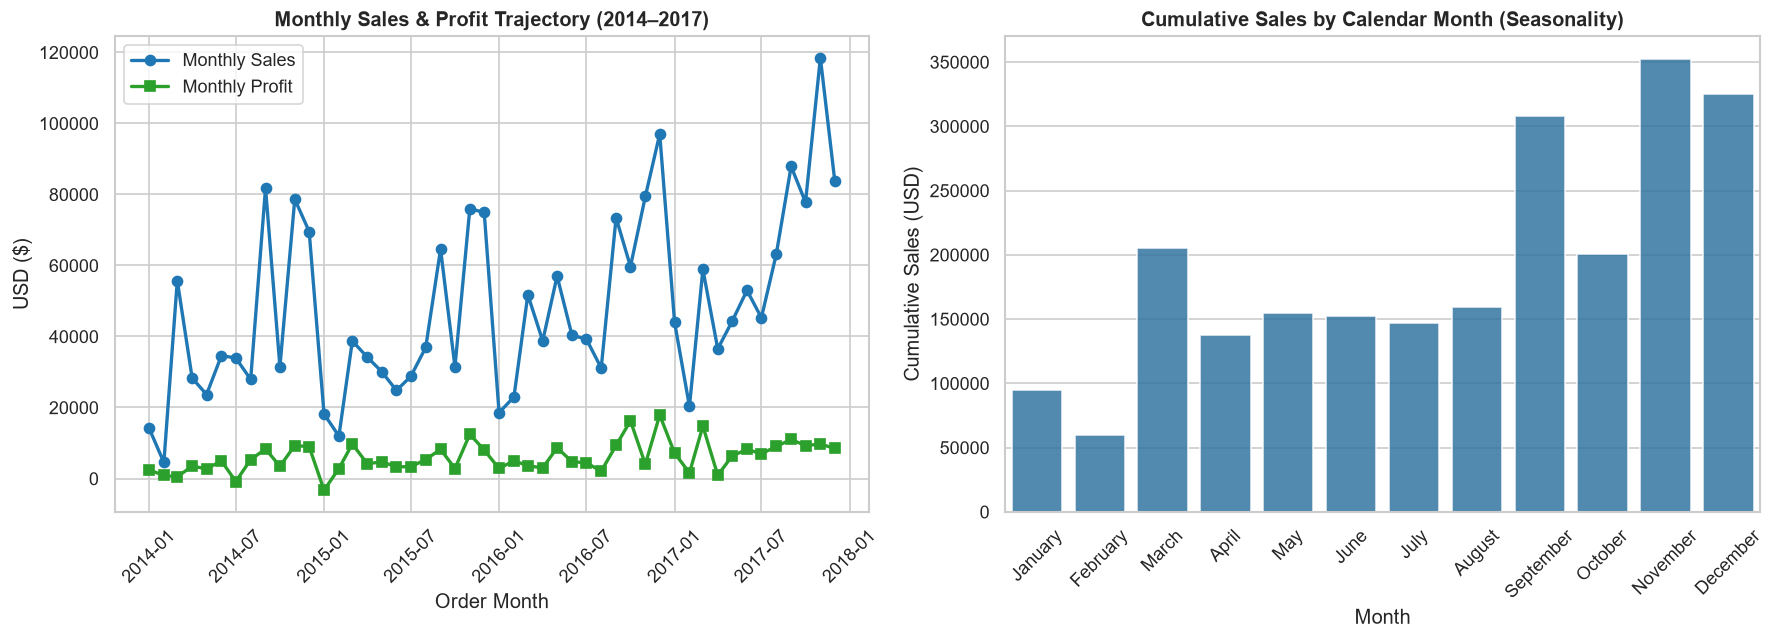

Top 3 Peak Months (Cumulative Sales):


,order_month_name,sales,profit,margin_pct
10,November,"352,461.07","35,468.43",10.06
11,December,"325,293.50","43,369.19",13.33
8,September,"307,649.95","36,857.48",11.98


In [5]:
monthly = (
    df.assign(year_month=df["order_date"].dt.to_period("M").dt.to_timestamp())
    .groupby("year_month", as_index=False)[["sales", "profit"]]
    .sum()
    .sort_values("year_month")
)
monthly["mom_sales_pct"] = monthly["sales"].pct_change() * 100

seasonality = (
    df.groupby(["order_month", "order_month_name"], as_index=False)[["sales", "profit"]]
    .sum()
    .sort_values("order_month")
)
seasonality["margin_pct"] = (seasonality["profit"] / seasonality["sales"]) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].plot(monthly["year_month"], monthly["sales"], marker="o", linewidth=2, label="Monthly Sales", color="#1f77b4")
axes[0].plot(monthly["year_month"], monthly["profit"], marker="s", linewidth=2, label="Monthly Profit", color="#2ca02c")
axes[0].set_title("Monthly Sales & Profit Trajectory (2014–2017)", fontweight="bold")
axes[0].set_xlabel("Order Month")
axes[0].set_ylabel("USD ($)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()

sns.barplot(data=seasonality, x="order_month_name", y="sales", ax=axes[1], color="#1f77b4", alpha=0.85)
axes[1].set_title("Cumulative Sales by Calendar Month (Seasonality)", fontweight="bold")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Cumulative Sales (USD)")
axes[1].tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

print("Top 3 Peak Months (Cumulative Sales):")
seasonality.sort_values("sales", ascending=False).head(3)[["order_month_name", "sales", "profit", "margin_pct"]]


**Seasonality & MoM Volatility Findings**:
- Strong **Q4 retail seasonality**: **November (`$352,461`)**, **December (`$325,294`)**, and **September (`$307,650`)** are the three highest-revenue months, while January and February consistently represent seasonal troughs (leading to sharp negative MoM swings each January followed by March/September rebounds).
- Inventory, fulfillment capacity, and promotional calendars should scale ahead of the **September–December** peak window.


## Section 5: Margin & Discount Elasticity Analysis

Evaluate how discount depth affects profit margin %, identify the exact discount threshold that drives profit negative, and inspect sub-category margin performance.


In [6]:
df["discount_tier"] = pd.cut(
    df["discount"],
    bins=[-0.01, 0.0, 0.10, 0.20, 0.40, 1.0],
    labels=["0% (None)", "1%–10%", "11%–20%", "21%–40%", ">40% (Clearance)"],
)

tier_summary = (
    df.groupby("discount_tier", observed=False, as_index=False)
    .agg(
        transactions=("row_id", "count"),
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        avg_margin_pct=("profit_margin_pct", "mean"),
        loss_rate_pct=("profit", lambda s: (s < 0).mean() * 100),
    )
)
tier_summary["weighted_margin_pct"] = (tier_summary["total_profit"] / tier_summary["total_sales"]) * 100
tier_summary


,discount_tier,transactions,total_sales,total_profit,avg_margin_pct,loss_rate_pct,weighted_margin_pct
0,0% (None),4798,"1,087,908.47","320,987.60",34.02,0.00,29.51
1,1%–10%,94,"54,369.35","9,029.18",15.58,4.26,16.61
2,11%–20%,3709,"792,152.89","91,756.30",17.48,13.99,11.58
3,21%–40%,460,"234,137.90","-35,817.47",-16.69,90.22,-15.30
4,>40% (Clearance),933,"128,632.25","-99,558.59",-108.90,100.00,-77.40


**Discount Threshold Discovery**:
- At **`0%` discount**, transactions yield a healthy **`29.51%` weighted margin** with **0.00% loss rate**.
- Between **`1%–20%` discount**, the business remains solidly profitable (`11%–20%` tier produces `$91,756.30` total profit, `11.58%` weighted margin, `13.99%` loss rate).
- **The Critical Tipping Point (`> 20%` Discount)**: Once discounts exceed **`20%`**, margins collapse precipitously—the **`21%–40%`** tier drops to **`-15.30%` weighted margin (`90.22%` loss rate)**, and **`> 40%`** clearance plunges to **`-77.40%` weighted margin (`100.00%` loss rate)**.


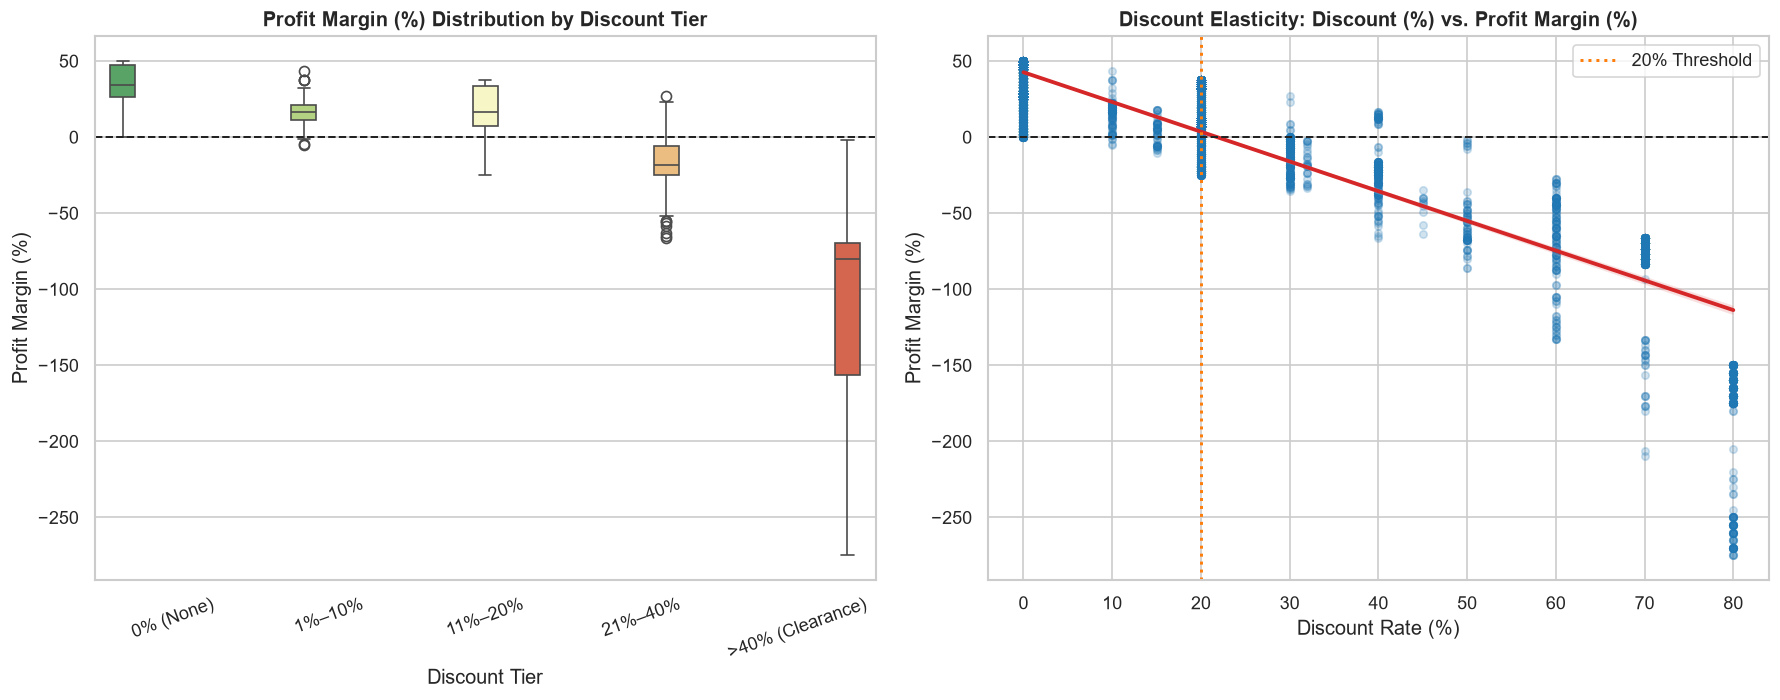

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Box plot of profit margin by discount tier
sns.boxplot(
    data=df,
    x="discount_tier",
    y="profit_margin_pct",
    ax=axes[0],
    palette="RdYlGn_r",
    hue="discount_tier",
    legend=False,
)
axes[0].axhline(0, color="#222222", linestyle="--", linewidth=1.2)
axes[0].set_title("Profit Margin (%) Distribution by Discount Tier", fontweight="bold")
axes[0].set_xlabel("Discount Tier")
axes[0].set_ylabel("Profit Margin (%)")
axes[0].tick_params(axis="x", rotation=20)

# Scatter regression plot: Discount % vs Profit Margin %
plot_df = df.assign(discount_pct=df["discount"] * 100)
sns.regplot(
    data=plot_df,
    x="discount_pct",
    y="profit_margin_pct",
    ax=axes[1],
    scatter_kws={"alpha": 0.2, "s": 20, "color": "#1f77b4"},
    line_kws={"color": "#d62728", "linewidth": 2.3},
)
axes[1].axhline(0, color="#222222", linestyle="--", linewidth=1.2)
axes[1].axvline(20, color="#ff7f0e", linestyle=":", linewidth=1.8, label="20% Threshold")
axes[1].set_title("Discount Elasticity: Discount (%) vs. Profit Margin (%)", fontweight="bold")
axes[1].set_xlabel("Discount Rate (%)")
axes[1].set_ylabel("Profit Margin (%)")
axes[1].legend()

fig.tight_layout()
plt.show()


**Discount Elasticity Visual Takeaways**:
- The regression line crosses the **0% profitability breakeven** right near the **20% discount threshold**.
- Every transaction bucket above `20%` shifts the entire interquartile range below zero, demonstrating that deep discounting is the primary structural driver of net operating losses.


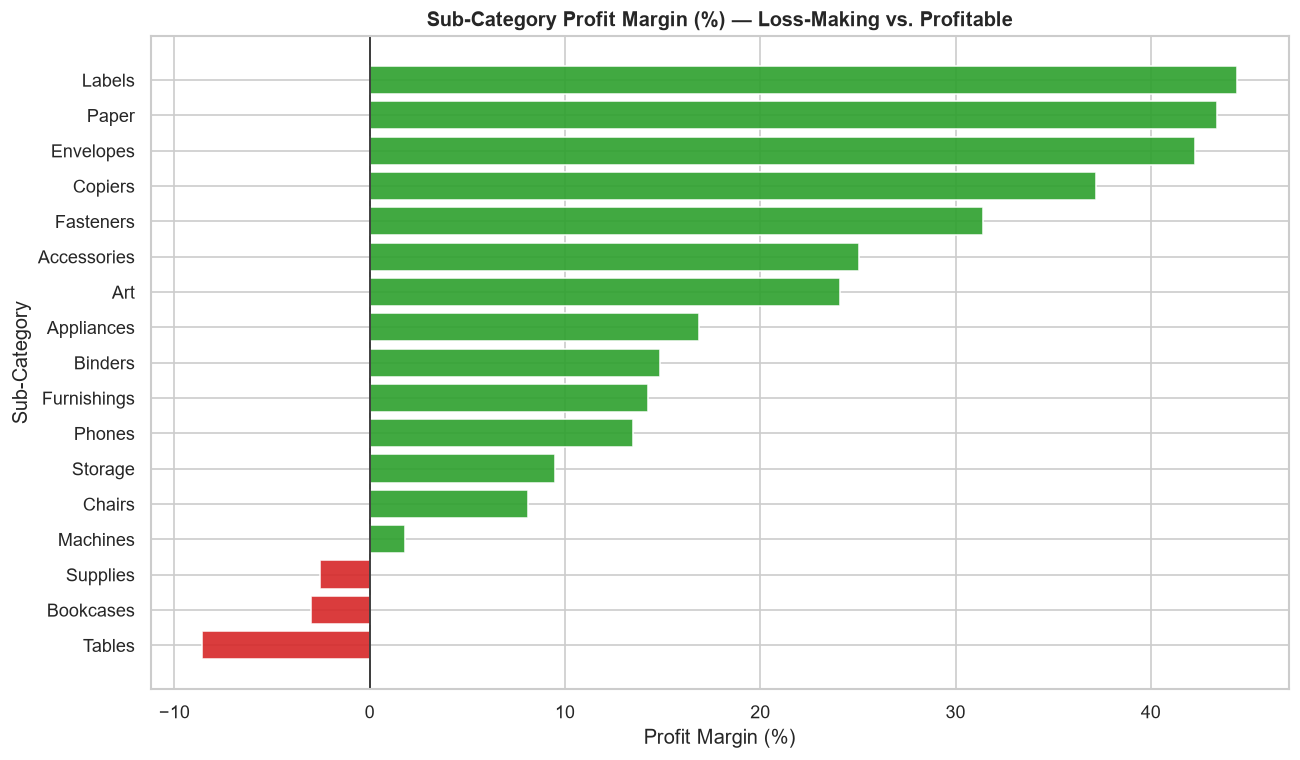

,category,sub_category,sales,profit,margin_pct
3,Furniture,Tables,"206,965.53","-17,725.48",-8.56
0,Furniture,Bookcases,"114,880.00","-3,472.56",-3.02
12,Office Supplies,Supplies,"46,673.54","-1,189.10",-2.55


In [8]:
subcat = (
    df.groupby(["category", "sub_category"], as_index=False)[["sales", "profit"]]
    .sum()
)
subcat["margin_pct"] = (subcat["profit"] / subcat["sales"]) * 100
subcat = subcat.sort_values("margin_pct", ascending=True)

fig, ax = plt.subplots(figsize=(11, 6.5))
colors = ["#d62728" if m < 0 else "#2ca02c" for m in subcat["margin_pct"]]
ax.barh(subcat["sub_category"], subcat["margin_pct"], color=colors, alpha=0.9)
ax.axvline(0, color="#222222", linewidth=1.0)
ax.set_title("Sub-Category Profit Margin (%) — Loss-Making vs. Profitable", fontweight="bold")
ax.set_xlabel("Profit Margin (%)")
ax.set_ylabel("Sub-Category")
fig.tight_layout()
plt.show()

subcat[subcat["profit"] < 0]


**Sub-Category Profitability Observations**:
- **Three sub-categories are net loss-makers**: **Tables (`-$17,725.48`, `-8.56%` margin)**, **Bookcases (`-$3,472.56`, `-3.02%` margin)**, and **Supplies (`-$1,189.10`, `-2.55%` margin)**.
- Conversely, **Labels (`+44.4%`)**, **Paper (`+43.4%`)**, **Envelopes (`+42.3%`)**, and **Copiers (`+37.2%`)** deliver exceptional operating margins.


## Section 6: Customer Segmentation & Regional Performance

Analyze segment contributions (`Consumer`, `Corporate`, `Home Office`), compute customer RFM tiers, and compare regional sales, profit, and discount exposure.


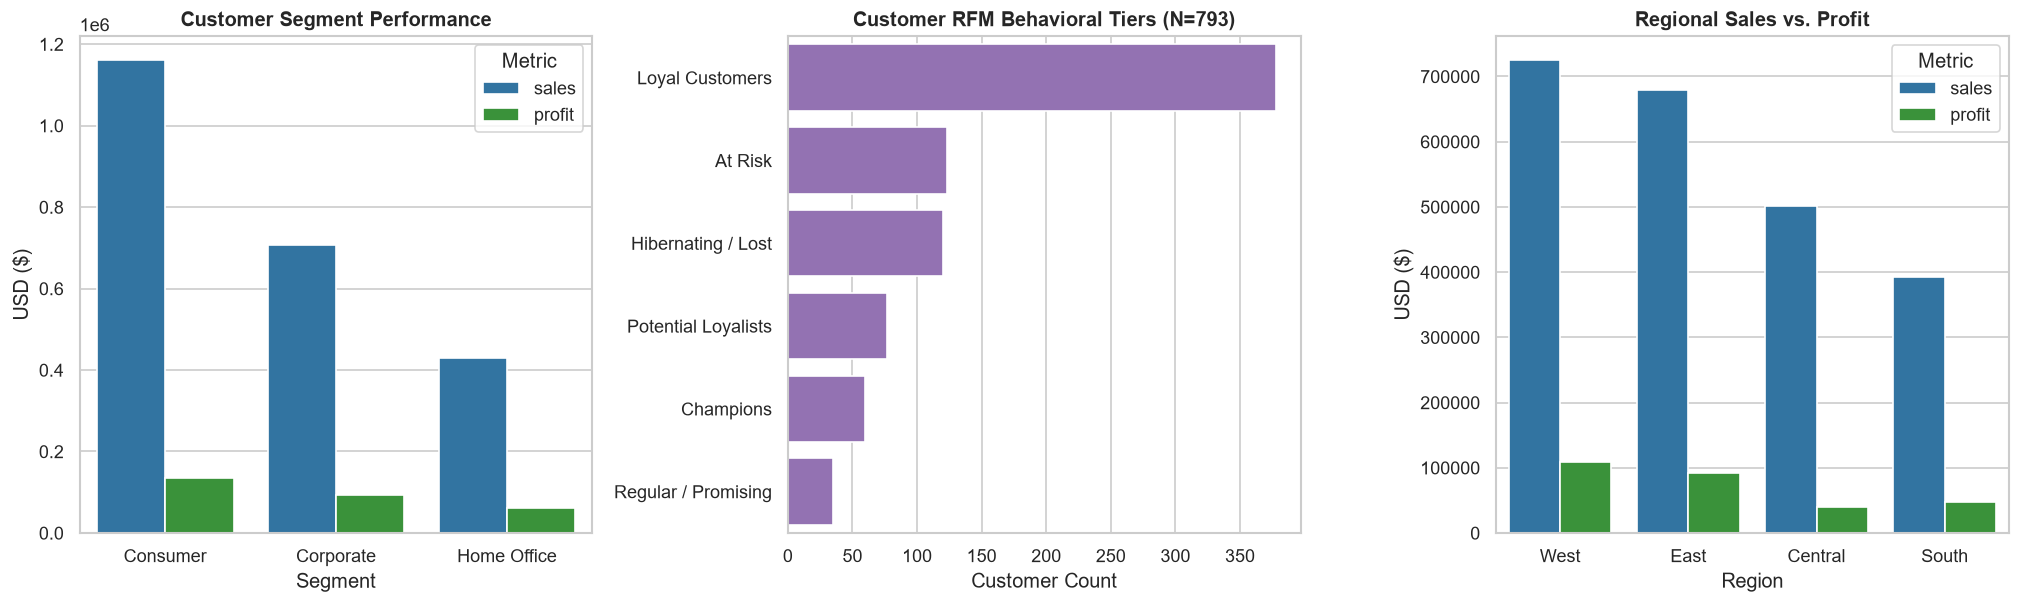

Segment Summary:


,segment,customers,orders,sales,profit,margin_pct
0,Consumer,409,2586,"1,161,401.34","134,119.21",11.55
1,Corporate,236,1514,"706,146.37","91,979.13",13.03
2,Home Office,148,909,"429,653.15","60,298.68",14.03


Regional Summary:


,region,orders,sales,profit,avg_discount_pct,margin_pct
3,West,1611,"725,457.82","108,418.45",10.93,14.94
1,East,1401,"678,781.24","91,522.78",14.54,13.48
0,Central,1175,"501,239.89","39,706.36",24.04,7.92
2,South,822,"391,721.91","46,749.43",14.73,11.93


RFM Tier Summary:


,rfm_tier,customers,avg_monetary,total_profit
3,Loyal Customers,378,"2,951.42","110,604.68"
1,Champions,60,"6,444.89","59,652.47"
0,At Risk,123,"2,967.50","54,186.10"
2,Hibernating / Lost,120,"2,230.75","40,517.77"
4,Potential Loyalists,77,"1,626.13","17,156.94"
5,Regular / Promising,35,"1,056.20","4,279.06"


In [9]:
ref_date = df["order_date"].max()
rfm = (
    df.groupby(["customer_id", "customer_name", "segment"], as_index=False)
    .agg(
        recency_days=("order_date", lambda s: (ref_date - s.max()).days),
        frequency=("order_id", "nunique"),
        monetary=("sales", "sum"),
        profit=("profit", "sum"),
    )
)

def assign_rfm(row: pd.Series) -> str:
    if row["recency_days"] <= 60 and row["frequency"] >= 8 and row["monetary"] >= 4000:
        return "Champions"
    if row["recency_days"] <= 120 and row["frequency"] >= 5:
        return "Loyal Customers"
    if row["recency_days"] <= 90 and row["frequency"] < 5:
        return "Potential Loyalists"
    if 121 <= row["recency_days"] <= 300 and row["frequency"] >= 4:
        return "At Risk"
    if row["recency_days"] > 300:
        return "Hibernating / Lost"
    return "Regular / Promising"

rfm["rfm_tier"] = rfm.apply(assign_rfm, axis=1)

seg_perf = (
    df.groupby("segment", as_index=False)
    .agg(customers=("customer_id", "nunique"), orders=("order_id", "nunique"), sales=("sales", "sum"), profit=("profit", "sum"))
    .assign(margin_pct=lambda d: (d["profit"] / d["sales"]) * 100)
    .sort_values("sales", ascending=False)
)

reg_perf = (
    df.groupby("region", as_index=False)
    .agg(orders=("order_id", "nunique"), sales=("sales", "sum"), profit=("profit", "sum"), avg_discount_pct=("discount", lambda s: s.mean() * 100))
    .assign(margin_pct=lambda d: (d["profit"] / d["sales"]) * 100)
    .sort_values("sales", ascending=False)
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

# 1. Segment Sales & Profit
seg_melt = seg_perf.melt(id_vars="segment", value_vars=["sales", "profit"], var_name="Metric", value_name="USD")
sns.barplot(data=seg_melt, x="segment", y="USD", hue="Metric", ax=axes[0], palette={"sales": "#1f77b4", "profit": "#2ca02c"})
axes[0].set_title("Customer Segment Performance", fontweight="bold")
axes[0].set_xlabel("Segment")
axes[0].set_ylabel("USD ($)")

# 2. RFM Tier Distribution
rfm_counts = rfm["rfm_tier"].value_counts().reset_index()
rfm_counts.columns = ["rfm_tier", "count"]
sns.barplot(data=rfm_counts, y="rfm_tier", x="count", ax=axes[1], color="#9467bd")
axes[1].set_title("Customer RFM Behavioral Tiers (N=793)", fontweight="bold")
axes[1].set_xlabel("Customer Count")
axes[1].set_ylabel("")

# 3. Regional Performance
reg_melt = reg_perf.melt(id_vars="region", value_vars=["sales", "profit"], var_name="Metric", value_name="USD")
sns.barplot(data=reg_melt, x="region", y="USD", hue="Metric", ax=axes[2], palette={"sales": "#1f77b4", "profit": "#2ca02c"})
axes[2].set_title("Regional Sales vs. Profit", fontweight="bold")
axes[2].set_xlabel("Region")
axes[2].set_ylabel("USD ($)")

fig.tight_layout()
plt.show()

print("Segment Summary:")
display(seg_perf)
print("Regional Summary:")
display(reg_perf)
print("RFM Tier Summary:")
display(rfm.groupby("rfm_tier", as_index=False).agg(customers=("customer_id", "count"), avg_monetary=("monetary", "mean"), total_profit=("profit", "sum")).sort_values("total_profit", ascending=False))


**Segmentation & Regional Performance Insights**:
- **Segment Mix**: `Consumer` generates roughly half of total revenue (`$1,161,401`), while `Home Office` achieves the highest operating margin (`14.03%`).
- **RFM Customer Base**: `Loyal Customers` (`$110,605` total profit across 378 customers) and `Champions` (`$59,652` across 60 customers) account for disproportionate cumulative profit, while `At Risk` (123 customers) and `Hibernating / Lost` (120 customers) represent targeted win-back opportunities.
- **Regional Margin Divergence**: **West** leads in both sales (`$725.5K`) and profit (`$108.4K`, `14.94%` margin). **Central** generates `$501.2K` in sales—more than **South** (`$391.7K`)—yet yields less profit (`$39.7K`, `7.92%` margin) due to its elevated **`24.04%` average discount rate** (vs. `10.93%–14.73%` in other regions).


## Section 7: Key Findings & Actionable Business Recommendations

### Key Quantitative Findings
1. **Strong Macro Trajectory with Q4 Seasonality**: Total 2014–2017 revenue reached **`$2,297,200.86`** with **`$286,397.02`** net profit (`12.47%` overall margin). Annual profit grew every year, peaking at `$93,439.27` in 2017, with strong Sept–Dec seasonal demand.
2. **Hard Profitability Cutoff Above 20% Discount**: Discounts of `0%–20%` remain profitable (`11.58%–29.51%` weighted margin), whereas discounts `> 20%` invert margins (`-15.30%` for `21%–40%` and `-77.40%` for `> 40%`), causing `90.22%` to `100.00%` loss-making line items.
3. **Localized Sub-Category Bleed**: Only 3 of 17 sub-categories lose money overall—**Tables (`-$17,725.48`)**, **Bookcases (`-$3,472.56`)**, and **Supplies (`-$1,189.10`)**—driven heavily by excessive discounting and freight-heavy furniture SKUs.
4. **Central Region Discount Leakage**: Central carries a `24.04%` average discount rate, depressing its margin (`7.92%`) to nearly half of West's (`14.94%`).

### Actionable Business Recommendations
1. **Enforce a 20% Discount Guardrail**: Require finance/management approval for any line-item discount exceeding `20%`, and replace blanket markdowns with bundled promotions pairing high-margin office supplies (`Labels`, `Paper`, `Envelopes`) with core hardware.
2. **Restructure Furniture Pricing & Logistics (Tables & Bookcases)**: Audit vendor costs, minimum order quantities, and regional shipping subsidies on `Tables` and `Bookcases`, and eliminate `> 20%` discounts in those two sub-categories immediately.
3. **Regional Pricing Reset in Central**: Align Central's promotional policy with West/East (`11%–15%` average discount ceiling); recovering even 4 percentage points of margin in Central adds **`~$20,000+`** in annual net profit on existing sales volume.
4. **RFM Retention & Q4 Capacity Scaling**: Launch automated win-back campaigns for the 123 `At Risk` customers and pre-position high-margin inventory (`Copiers`, `Phones`, `Accessories`, `Paper`) ahead of the September–December peak season.
